# COVID-19 Dataset — Exploratory Data Analysis (EDA)

## Project Objective
Perform exploratory data analysis on the provided early COVID-19 dataset to understand:
- dataset structure and data quality
- missing values and duplicate records
- distributions of confirmed, suspected, recovered and death counts
- changes in reported cases over time
- regions with the highest reported confirmed cases
- relationships among the numerical variables

> **Important:** The analysis preserves the dataset's original country/province labels. Exact duplicate rows are removed only for analyses where duplicate records would otherwise double-count observations; the raw dataset itself is not overwritten.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

FILE = "2019_nC0v_20200121_20200126_SUMMARY.csv"

df = pd.read_csv(FILE)

# Parse date/time values and numeric columns.
df["Date last updated"] = pd.to_datetime(
    df["Date last updated"].astype(str).str.strip(),
    format="mixed",
    errors="coerce"
)

numeric_cols = ["Confirmed", "Suspected", "Recovered", "Deaths"]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df_raw = df.copy()
df_analysis = df.drop_duplicates().copy()

print("Raw shape:", df_raw.shape)
print("Shape after removing exact duplicate rows for analysis:", df_analysis.shape)


Raw shape: (368, 7)
Shape after removing exact duplicate rows for analysis: (349, 7)


## 1. Dataset Overview

In [2]:
print("Rows:", df_raw.shape[0])
print("Columns:", df_raw.shape[1])
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types:")
display(df_raw.dtypes.to_frame("dtype"))

print("\nDate range:")
print(df_raw["Date last updated"].min(), "to", df_raw["Date last updated"].max())

print("\nNumber of unique countries:", df_raw["Country"].nunique())
print("Number of unique province/state labels:", df_raw["Province/State"].nunique())


Rows: 368
Columns: 7

Column names:
['Province/State', 'Country', 'Date last updated', 'Confirmed', 'Suspected', 'Recovered', 'Deaths']

Data types:


,dtype
Province/State,object
Country,object
Date last updated,datetime64[ns]
Confirmed,float64
Suspected,float64
Recovered,float64
Deaths,float64



Date range:
2020-01-21 00:00:00 to 2020-01-26 11:00:00

Number of unique countries: 21
Number of unique province/state labels: 39


## 2. First Look at the Data

In [3]:
display(df_raw.head(10))


,Province/State,Country,Date last updated,Confirmed,Suspected,Recovered,Deaths
0,Shanghai,Mainland China,2020-01-21,9.00,10.00,NaN,NaN
1,Yunnan,Mainland China,2020-01-21,1.00,NaN,NaN,NaN
2,Beijing,Mainland China,2020-01-21,10.00,NaN,NaN,NaN
3,Taiwan,Mainland China,2020-01-21,1.00,NaN,NaN,NaN
4,Jilin,Mainland China,2020-01-21,NaN,1.00,NaN,NaN
5,Sichuan,Mainland China,2020-01-21,2.00,1.00,NaN,NaN
6,Tianjin,Mainland China,2020-01-21,2.00,NaN,NaN,NaN
7,Ningxia,Mainland China,2020-01-21,NaN,1.00,NaN,NaN
8,Anhui,Mainland China,2020-01-21,NaN,3.00,NaN,NaN
9,Shandong,Mainland China,2020-01-21,1.00,NaN,NaN,NaN


## 3. Missing Values

,Missing Count,Missing Percentage
Deaths,344,93.48
Recovered,332,90.22
Suspected,280,76.09
Province/State,64,17.39
Confirmed,29,7.88
Date last updated,0,0.00
Country,0,0.00


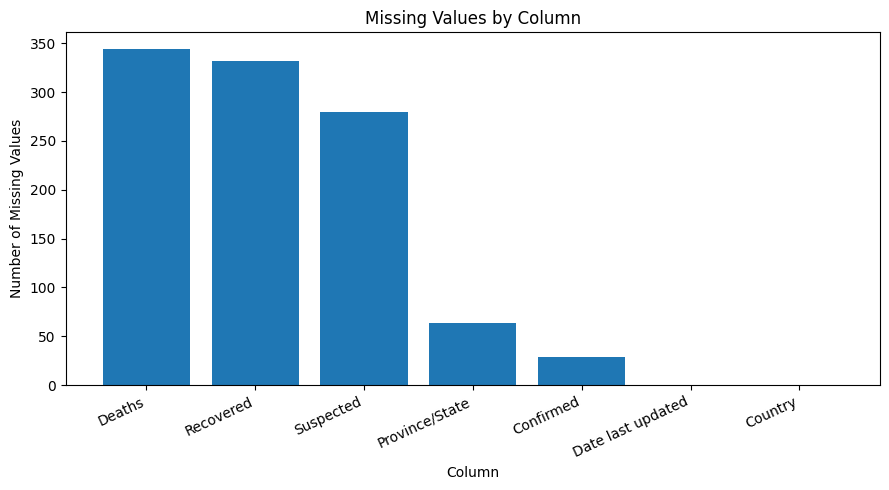

In [4]:
missing = df_raw.isna().sum().sort_values(ascending=False)
missing_pct = (df_raw.isna().mean() * 100).sort_values(ascending=False)

missing_table = pd.DataFrame({
    "Missing Count": missing,
    "Missing Percentage": missing_pct.round(2)
})
display(missing_table)

plt.figure(figsize=(9, 5))
plt.bar(missing.index, missing.values)
plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Missing-value observation
The dataset has substantial missingness in `Deaths`, `Recovered`, and `Suspected`. This is expected to affect calculations based on those fields, so the notebook uses pandas' default missing-value handling rather than treating missing values as confirmed zero values.

## 4. Duplicate Records

In [5]:
duplicate_count = df_raw.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

if duplicate_count:
    display(df_raw[df_raw.duplicated(keep=False)].sort_values(df_raw.columns.tolist()).head(20))


Exact duplicate rows: 19


,Province/State,Country,Date last updated,Confirmed,Suspected,Recovered,Deaths
246,Hainan,Mainland China,2020-01-25 12:00:00,19.00,NaN,NaN,NaN
292,Hainan,Mainland China,2020-01-25 12:00:00,19.00,NaN,NaN,NaN
258,Hong Kong,Hong Kong,2020-01-25 12:00:00,5.00,244.00,NaN,NaN
304,Hong Kong,Hong Kong,2020-01-25 12:00:00,5.00,244.00,NaN,NaN
268,Illinois,US,2020-01-25 12:00:00,1.00,NaN,NaN,NaN
312,Illinois,US,2020-01-25 12:00:00,1.00,NaN,NaN,NaN
256,Inner Mongolia,Mainland China,2020-01-25 12:00:00,7.00,NaN,NaN,NaN
301,Inner Mongolia,Mainland China,2020-01-25 12:00:00,7.00,NaN,NaN,NaN
260,Jilin,Mainland China,2020-01-25 12:00:00,4.00,NaN,NaN,NaN
306,Jilin,Mainland China,2020-01-25 12:00:00,4.00,NaN,NaN,NaN


For time-series aggregation, exact duplicate rows are removed using `drop_duplicates()` so that identical records are not counted twice. The original 368-row dataset remains unchanged in the project.

## 5. Descriptive Statistics

In [6]:
display(df_raw[numeric_cols].describe().T)


,count,mean,std,min,25%,50%,75%,max
Confirmed,339.00,30.35,112.56,1.00,2.00,5.00,18.00,"1,058.00"
Suspected,88.00,22.61,48.18,1.00,1.00,4.00,22.00,244.00
Recovered,36.00,7.72,13.31,1.00,1.00,1.50,2.00,42.00
Deaths,24.00,11.04,17.52,1.00,1.00,1.00,18.75,52.00


## 6. Distribution of Numerical Variables

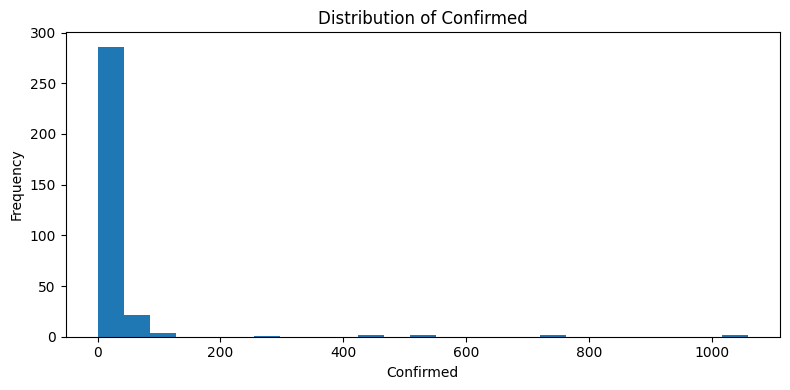

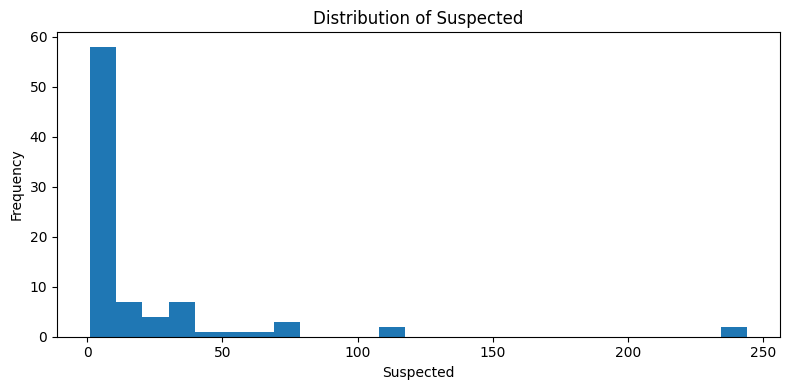

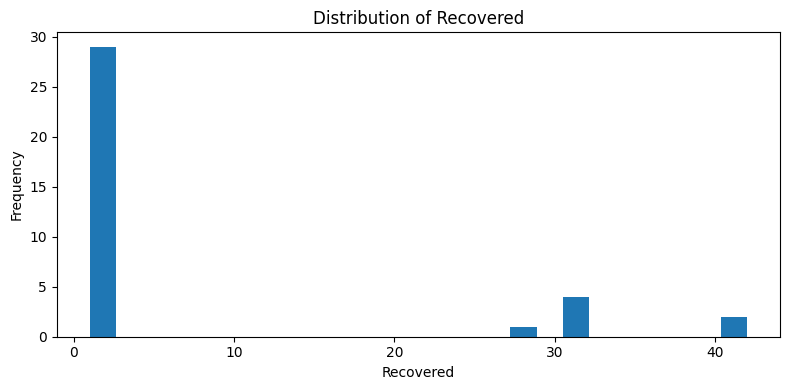

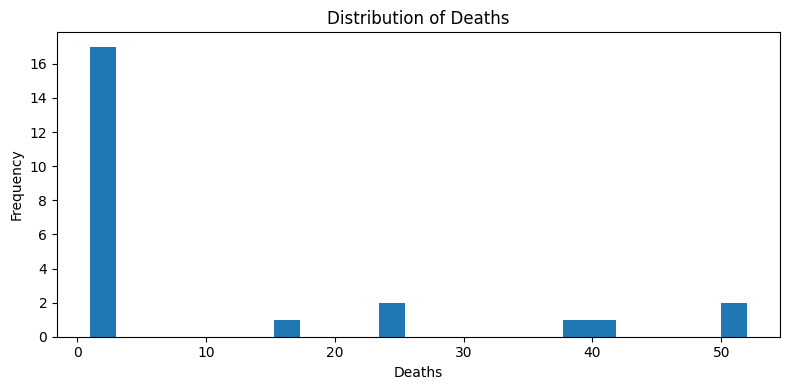

In [7]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(df_analysis[col].dropna(), bins=25)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


## 7. Boxplots and Outlier View

/tmp/ipykernel_479/237286159.py:2: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([df_analysis[c].dropna() for c in numeric_cols], labels=numeric_cols)


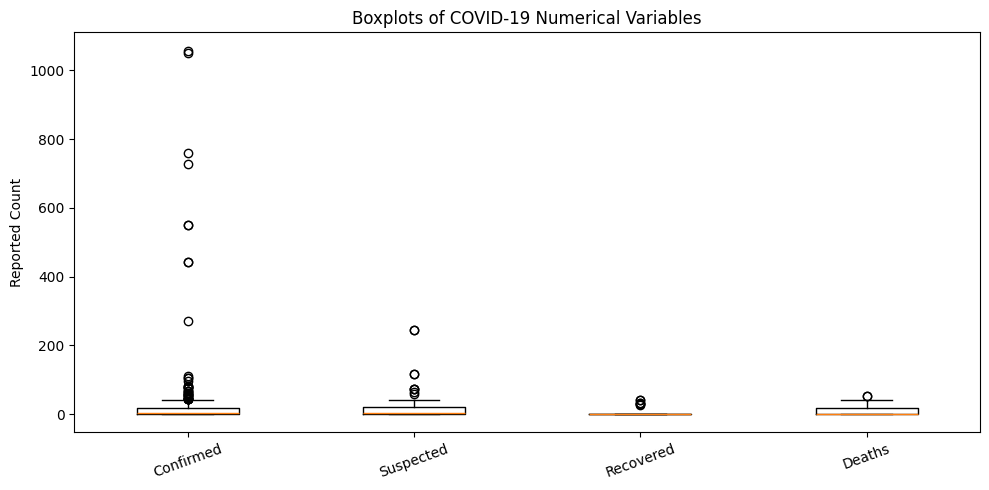

In [8]:
plt.figure(figsize=(10, 5))
plt.boxplot([df_analysis[c].dropna() for c in numeric_cols], labels=numeric_cols)
plt.title("Boxplots of COVID-19 Numerical Variables")
plt.ylabel("Reported Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


The distributions are strongly right-skewed because a small number of observations have much larger case counts than most regions.

## 8. Country Frequency

,Number of Records
Country,
Mainland China,266
US,14
Japan,9
South Korea,9
Thailand,9
Singapore,7
Hong Kong,7
Macau,7
Taiwan,7


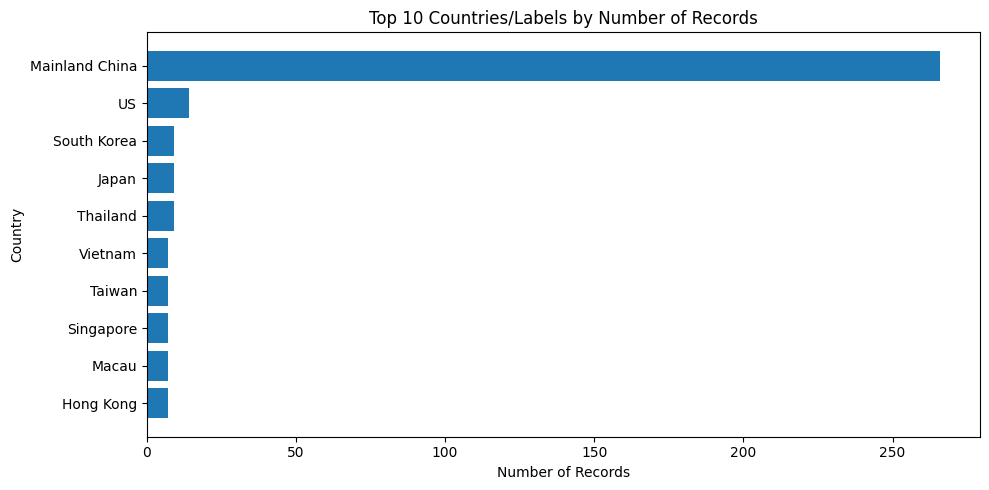

In [9]:
country_counts = df_raw["Country"].value_counts()
display(country_counts.head(15).to_frame("Number of Records"))

plt.figure(figsize=(10, 5))
top = country_counts.head(10).sort_values()
plt.barh(top.index, top.values)
plt.title("Top 10 Countries/Labels by Number of Records")
plt.xlabel("Number of Records")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


## 9. Highest Confirmed-Case Observations

In [10]:
top_confirmed = df_analysis.sort_values("Confirmed", ascending=False).head(10)
display(top_confirmed[
    ["Province/State", "Country", "Date last updated",
     "Confirmed", "Suspected", "Recovered", "Deaths"]
])


,Province/State,Country,Date last updated,Confirmed,Suspected,Recovered,Deaths
322,Hubei,Mainland China,2020-01-26 11:00:00,"1,058.00",NaN,42.00,52.00
278,Hubei,Mainland China,2020-01-25 22:00:00,"1,052.00",NaN,42.00,52.00
234,Hubei,Mainland China,2020-01-25 12:00:00,761.00,NaN,32.00,40.00
190,Hubei,Mainland China,2020-01-25 00:00:00,729.00,NaN,32.00,39.00
111,Hubei,Mainland China,2020-01-24 00:00:00,549.00,NaN,31.00,24.00
149,Hubei,Mainland China,2020-01-24 12:00:00,549.00,NaN,31.00,24.00
40,Hubei,Mainland China,2020-01-22 12:00:00,444.00,NaN,NaN,NaN
78,Hubei,Mainland China,2020-01-23 12:00:00,444.00,NaN,28.00,17.00
16,Hubei,Mainland China,2020-01-21 00:00:00,270.00,11.00,NaN,NaN
323,Guangdong,Mainland China,2020-01-26 11:00:00,111.00,NaN,2.00,NaN


## 10. Time-Series Analysis

,Confirmed,Suspected,Recovered,Deaths
Date last updated,,,,
2020-01-21 00:00:00,332.00,169.00,NaN,NaN
2020-01-22 12:00:00,555.00,137.00,NaN,NaN
2020-01-23 12:00:00,653.00,144.00,30.00,18.00
2020-01-24 00:00:00,881.00,115.00,34.00,26.00
2020-01-24 12:00:00,939.00,159.00,36.00,26.00
2020-01-24 16:00:00,2.00,NaN,NaN,NaN
2020-01-25 00:00:00,"1,354.00",73.00,38.00,41.00
2020-01-25 12:00:00,"2,207.00",508.00,45.00,46.00
2020-01-25 22:00:00,"1,156.00",NaN,43.00,52.00


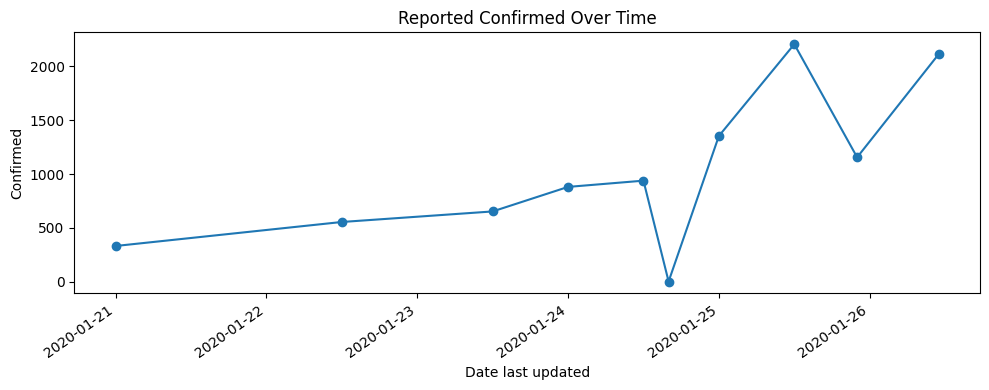

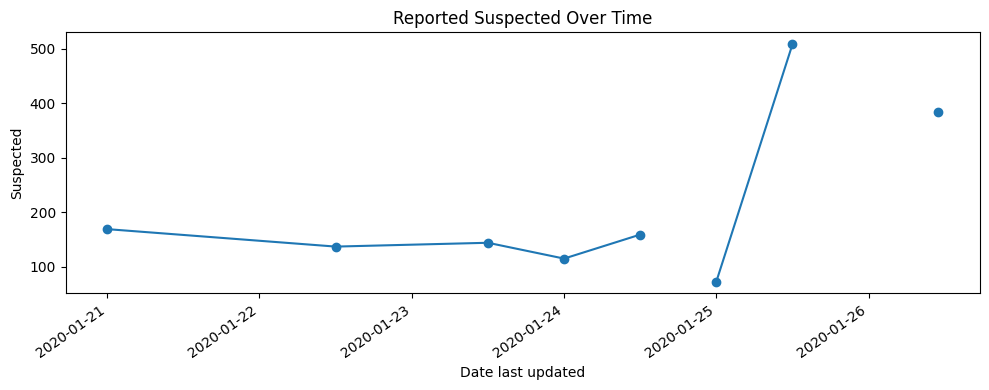

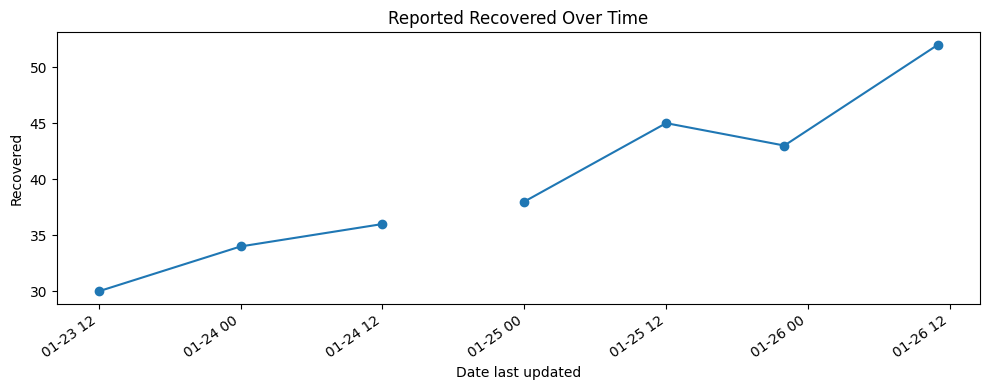

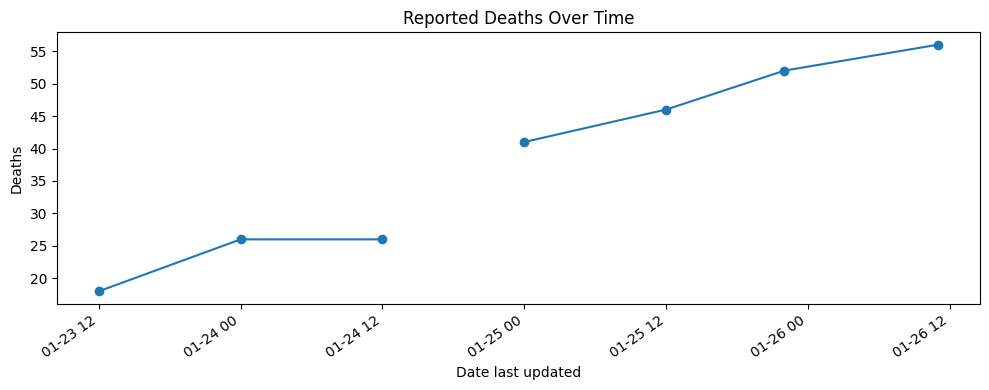

In [11]:
daily = (
    df_analysis
    .groupby("Date last updated")[numeric_cols]
    .sum(min_count=1)
    .sort_index()
)

display(daily)

for col in numeric_cols:
    plt.figure(figsize=(10, 4))
    plt.plot(daily.index, daily[col], marker="o")
    plt.title(f"Reported {col} Over Time")
    plt.xlabel("Date last updated")
    plt.ylabel(col)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


### Important interpretation note
The dataset contains several timestamps on the same calendar day. Therefore, this analysis treats each timestamp as a separate reported snapshot rather than collapsing everything to a calendar date.

## 11. Latest Snapshot — Highest Confirmed Cases

Latest timestamp: 2020-01-26 11:00:00
Number of records in latest snapshot: 46


,Province/State,Country,Confirmed,Suspected,Recovered,Deaths
322,Hubei,Mainland China,"1,058.00",NaN,42.00,52.00
323,Guangdong,Mainland China,111.00,NaN,2.00,NaN
324,Zhejiang,Mainland China,104.00,NaN,1.00,NaN
325,Henan,Mainland China,83.00,3.00,NaN,1.00
326,Chongqing,Mainland China,75.00,NaN,NaN,NaN
327,Hunan,Mainland China,69.00,NaN,NaN,NaN
328,Beijing,Mainland China,68.00,NaN,2.00,NaN
329,Anhui,Mainland China,60.00,4.00,NaN,NaN
330,Shandong,Mainland China,46.00,NaN,NaN,NaN
331,Sichuan,Mainland China,44.00,4.00,NaN,NaN


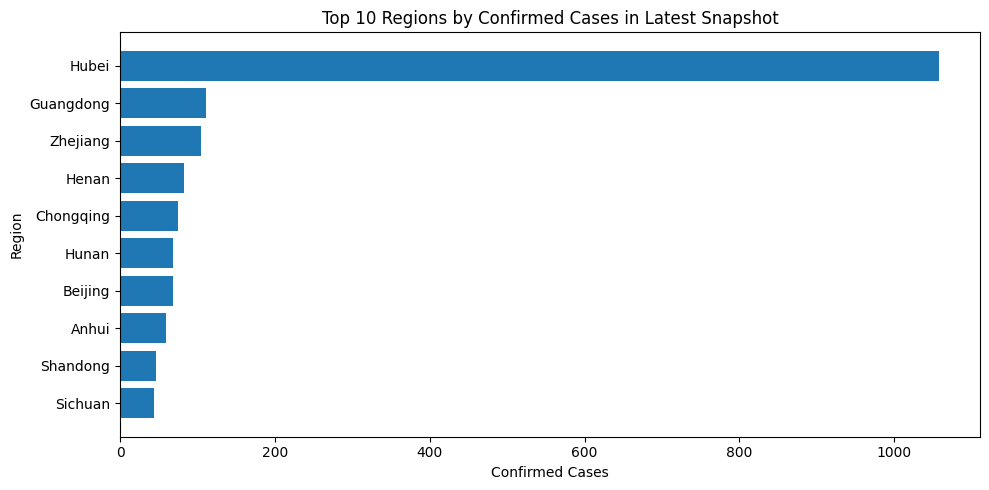

In [12]:
latest_timestamp = df_analysis["Date last updated"].max()
latest = df_analysis[df_analysis["Date last updated"] == latest_timestamp].copy()

print("Latest timestamp:", latest_timestamp)
print("Number of records in latest snapshot:", len(latest))

top_latest = latest.sort_values("Confirmed", ascending=False).head(10)
display(top_latest[
    ["Province/State", "Country", "Confirmed", "Suspected", "Recovered", "Deaths"]
])

plt.figure(figsize=(10, 5))
plot_data = top_latest.sort_values("Confirmed")
labels = plot_data["Province/State"].fillna(plot_data["Country"])
plt.barh(labels, plot_data["Confirmed"])
plt.title("Top 10 Regions by Confirmed Cases in Latest Snapshot")
plt.xlabel("Confirmed Cases")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


## 12. Confirmed vs Suspected Cases

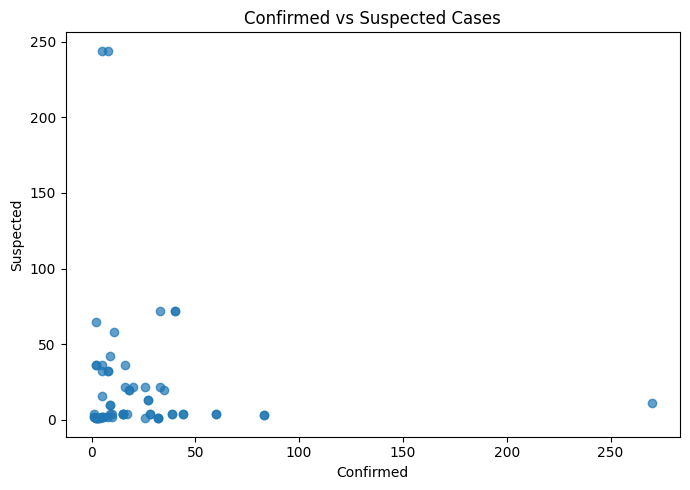

Correlation between Confirmed and Suspected:
-0.08608885364308529


In [13]:
scatter = df_analysis[["Confirmed", "Suspected"]].dropna()

plt.figure(figsize=(7, 5))
plt.scatter(scatter["Confirmed"], scatter["Suspected"], alpha=0.7)
plt.title("Confirmed vs Suspected Cases")
plt.xlabel("Confirmed")
plt.ylabel("Suspected")
plt.tight_layout()
plt.show()

print("Correlation between Confirmed and Suspected:")
print(scatter["Confirmed"].corr(scatter["Suspected"]))


## 13. Correlation Analysis

,Confirmed,Suspected,Recovered,Deaths
Confirmed,1.00,-0.09,0.98,0.99
Suspected,-0.09,1.00,-0.65,NaN
Recovered,0.98,-0.65,1.00,0.92
Deaths,0.99,NaN,0.92,1.00


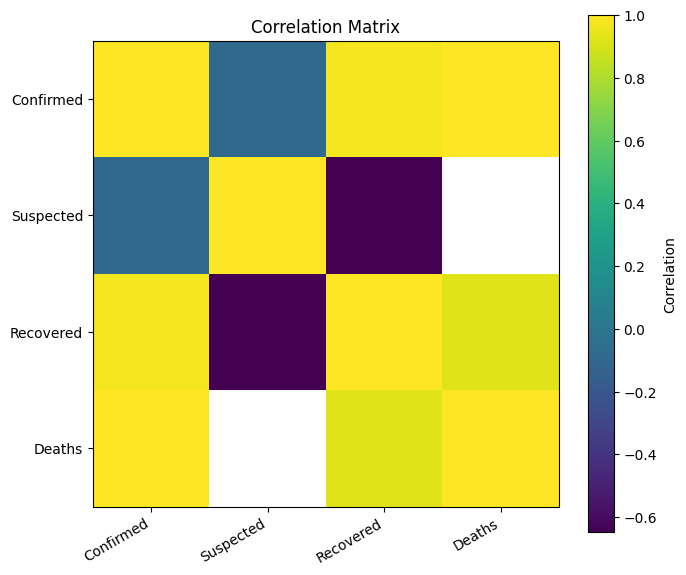

In [14]:
corr = df_analysis[numeric_cols].corr()
display(corr.round(3))

plt.figure(figsize=(7, 6))
plt.imshow(corr, interpolation="nearest")
plt.colorbar(label="Correlation")
plt.xticks(range(len(numeric_cols)), numeric_cols, rotation=30, ha="right")
plt.yticks(range(len(numeric_cols)), numeric_cols)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


## 14. Key Findings

In [15]:
# Generate a few reproducible headline statistics.
latest_totals = latest[numeric_cols].sum(min_count=1)

print("KEY FINDINGS")
print("-" * 60)
print(f"1. Raw dataset size: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns.")
print(f"2. Exact duplicate rows: {df_raw.duplicated().sum()}.")
print(f"3. Unique country labels: {df_raw['Country'].nunique()}.")
print(f"4. Date/time range: {df_raw['Date last updated'].min()} to {df_raw['Date last updated'].max()}.")
print(f"5. Latest snapshot confirmed total: {latest_totals['Confirmed']:,.0f}.")
print(f"6. Latest snapshot recovered total: {latest_totals['Recovered']:,.0f}.")
print(f"7. Latest snapshot deaths total: {latest_totals['Deaths']:,.0f}.")
print(f"8. Region with highest confirmed count in latest snapshot: "
      f"{top_latest.iloc[0]['Province/State'] if pd.notna(top_latest.iloc[0]['Province/State']) else top_latest.iloc[0]['Country']} "
      f"({top_latest.iloc[0]['Confirmed']:,.0f} confirmed).")
print("-" * 60)


KEY FINDINGS
------------------------------------------------------------
1. Raw dataset size: 368 rows × 7 columns.
2. Exact duplicate rows: 19.
3. Unique country labels: 21.
4. Date/time range: 2020-01-21 00:00:00 to 2020-01-26 11:00:00.
5. Latest snapshot confirmed total: 2,116.
6. Latest snapshot recovered total: 52.
7. Latest snapshot deaths total: 56.
8. Region with highest confirmed count in latest snapshot: Hubei (1,058 confirmed).
------------------------------------------------------------


## 15. Conclusion

The EDA shows a dataset with a small number of variables but considerable missing data and some exact duplicate records. The numerical variables are highly unevenly distributed, with a few regions contributing much larger reported counts than the majority of observations.

The time-series section shows rapid growth in reported confirmed cases across the available snapshots. The latest available snapshot in this file has the largest reported confirmed total, and Hubei is the highest-confirmed region in that snapshot.

### Data-quality considerations
1. Missing values are common, especially in `Deaths`, `Recovered`, and `Suspected`.
2. There are exact duplicate rows, so duplicates should be handled before aggregating observations.
3. Country labels are not fully standardized (for example, the file contains both `US` and `United States`, and both `China` and `Mainland China`). This notebook preserves the original labels rather than silently remapping them.
4. The data covers only the period available in the supplied file, so conclusions should not be generalized beyond this dataset's time range.


## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

**Dataset:** User-provided COVID-19 summary CSV.
